# Driver Safety Monitor — Feature Analysis

This notebook explores the feature dataset built by `src/build_dataset.py`. It contains four facial biomarkers extracted from two sources:

- **dataset_new**: ~1,400 rows from the public yawn/no_yawn image dataset.
- **own**: ~2,100 rows from personal recordings using `src/record_samples.py`.

**Features:**
| Feature | Description |
|---------|-------------|
| EAR | Eye Aspect Ratio — measures eye openness |
| MAR | Mouth Aspect Ratio — measures mouth openness (yawn detection) |
| yaw | Horizontal head turn angle (degrees) |
| pitch | Vertical head tilt angle (degrees) |

**Labels (not all rows have all labels):**
| Label | Source | Values |
|-------|--------|--------|
| yawn | dataset_new | 0 = no_yawn, 1 = yawn |
| eyes_closed | own | 0 = eyes open, 1 = eyes closed |
| looking_away | own | 0 = facing forward, 1 = looking away |

In [1]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# Aesthetics
sns.set_theme(style='darkgrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

# Load features.csv (relative to notebooks/ folder)
CSV_PATH = Path('../data/features.csv')
df_raw = pd.read_csv(CSV_PATH)

# Convert label columns to numeric where available
for col in ['yawn', 'eyes_closed', 'looking_away']:
    df_raw[col] = pd.to_numeric(df_raw[col], errors='coerce')

print(f'Loaded {len(df_raw):,} rows from {CSV_PATH}')
df_raw.head()

Loaded 3,534 rows from ../data/features.csv


,EAR,MAR,yaw,pitch,source,session,yawn,eyes_closed,looking_away
0,0.301258,0.891425,26.441494,-11.753503,dataset_new,train/yawn,1.0,NaN,NaN
1,0.276218,1.092771,31.939137,-10.284990,dataset_new,train/yawn,1.0,NaN,NaN
2,0.304589,0.740211,31.845334,-12.648152,dataset_new,train/yawn,1.0,NaN,NaN
3,0.350645,0.998458,-6.629705,20.345177,dataset_new,train/yawn,1.0,NaN,NaN
4,0.230789,0.621627,-12.177589,9.904227,dataset_new,train/yawn,1.0,NaN,NaN


## 1. Class Counts

First we check how many samples exist per source and per label value. A large class imbalance (many more 0s than 1s) could bias a classifier, so we want the classes to be reasonably balanced.

=== Rows per source ===
source
own            2105
dataset_new    1429

           yawn  ( 1429 labelled rows): 0=720, 1=709
    eyes_closed  ( 1469 labelled rows): 0=949, 1=520
   looking_away  ( 1076 labelled rows): 0=484, 1=592


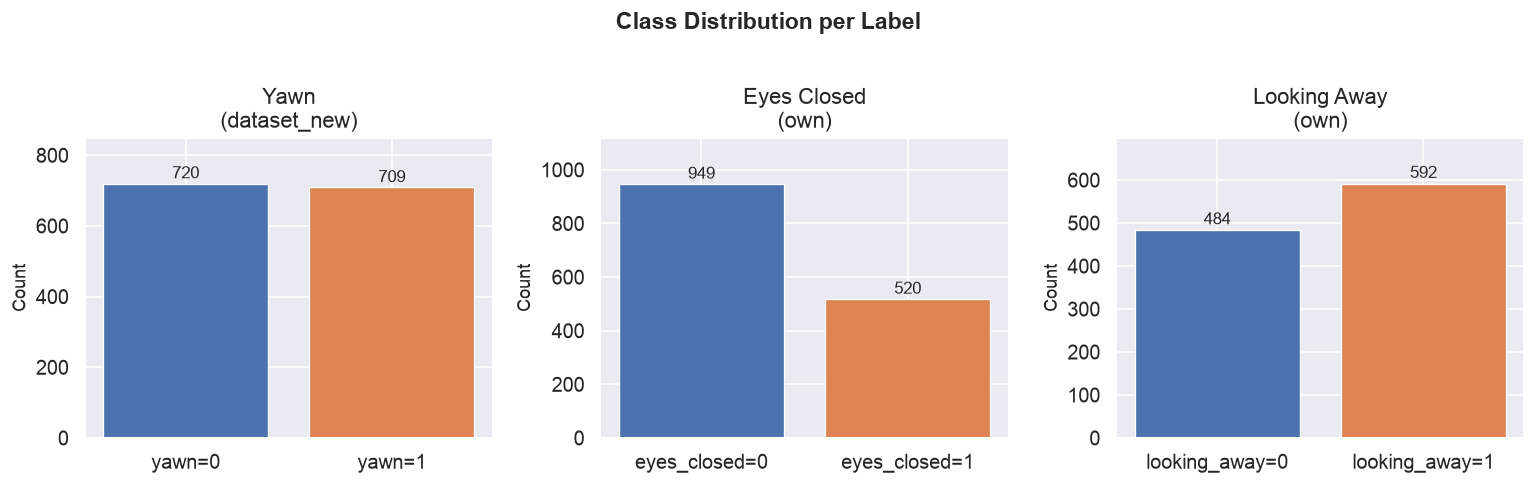

In [2]:
print('=== Rows per source ===')
print(df_raw['source'].value_counts().to_string())
print()

label_cols = ['yawn', 'eyes_closed', 'looking_away']
for col in label_cols:
    sub = df_raw[col].dropna()
    counts = sub.value_counts().sort_index()
    labels_str = ', '.join(f'{int(k)}={v}' for k, v in counts.items())
    print(f'{col:>15}  ({len(sub):>5} labelled rows): {labels_str}')

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
nice_names = {'yawn': 'Yawn\n(dataset_new)',
              'eyes_closed': 'Eyes Closed\n(own)',
              'looking_away': 'Looking Away\n(own)'}
colors = ['#4C72B0', '#DD8452']

for ax, col in zip(axes, label_cols):
    sub = df_raw[col].dropna().astype(int)
    counts = sub.value_counts().sort_index()
    bars = ax.bar([f'{col}=0', f'{col}=1'], counts.values, color=colors, edgecolor='white', linewidth=0.8)
    ax.set_title(nice_names[col])
    ax.set_ylabel('Count')
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
                str(bar.get_height()), ha='center', va='bottom', fontsize=10)
    ax.set_ylim(0, max(counts.values) * 1.18)

plt.suptitle('Class Distribution per Label', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('../results/class_counts.png', bbox_inches='tight')
plt.show()

## 2. Missing Values

Because **yawn** comes from `dataset_new` and **eyes_closed / looking_away** come from personal recordings, each label is only populated for its respective source. The empty cells in the other source are by design, not a data error. All four feature columns (EAR, MAR, yaw, pitch) should be complete with no missing values.

              Missing Count  Missing %
EAR                       0        0.0
MAR                       0        0.0
yaw                       0        0.0
pitch                     0        0.0
source                    0        0.0
session                   0        0.0
yawn                   2105       59.6
eyes_closed            2065       58.4
looking_away           2458       69.6


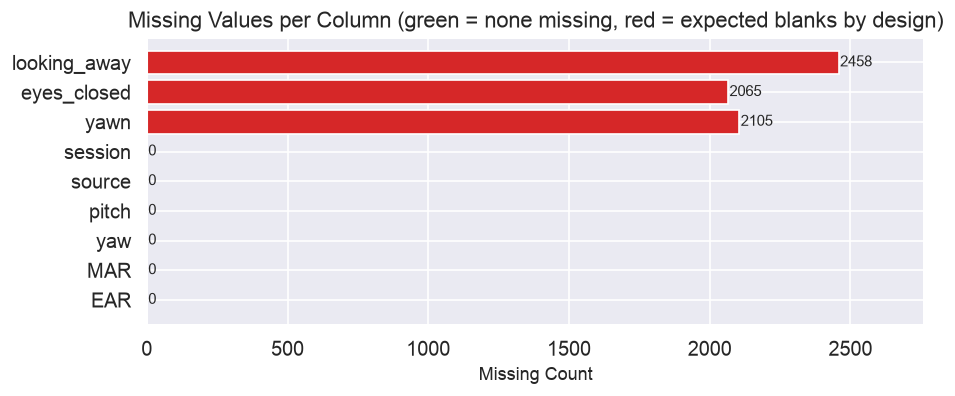

In [3]:
missing = df_raw.isnull().sum()
pct = (missing / len(df_raw) * 100).round(1)
summary = pd.DataFrame({'Missing Count': missing, 'Missing %': pct})
print(summary.to_string())

fig, ax = plt.subplots(figsize=(8, 3.5))
bar_colors = ['#2ca02c' if v == 0 else '#d62728' for v in missing.values]
bars = ax.barh(missing.index, missing.values, color=bar_colors, edgecolor='white')
for bar, val in zip(bars, missing.values):
    ax.text(val + 5, bar.get_y() + bar.get_height() / 2,
            f'{val}', va='center', fontsize=9)
ax.set_xlabel('Missing Count')
ax.set_title('Missing Values per Column (green = none missing, red = expected blanks by design)')
ax.set_xlim(0, missing.max() * 1.12 + 10)
plt.tight_layout()
plt.savefig('../results/missing_values.png', bbox_inches='tight')
plt.show()

## 3. Feature Distributions by Label

### 3a. EAR / MAR / Yaw / Pitch  ×  Yawn  (dataset_new)

These boxplots compare the four biomarkers between **yawning** (1) and **not yawning** (0) frames from `dataset_new`.

- **MAR** should be the clearest discriminator: the mouth opens wide during a yawn, so MAR rises sharply.
- **EAR** may also drop slightly during a yawn because people partially close their eyes.
- **Yaw** and **Pitch** capture incidental head movement; they may not separate the classes strongly.

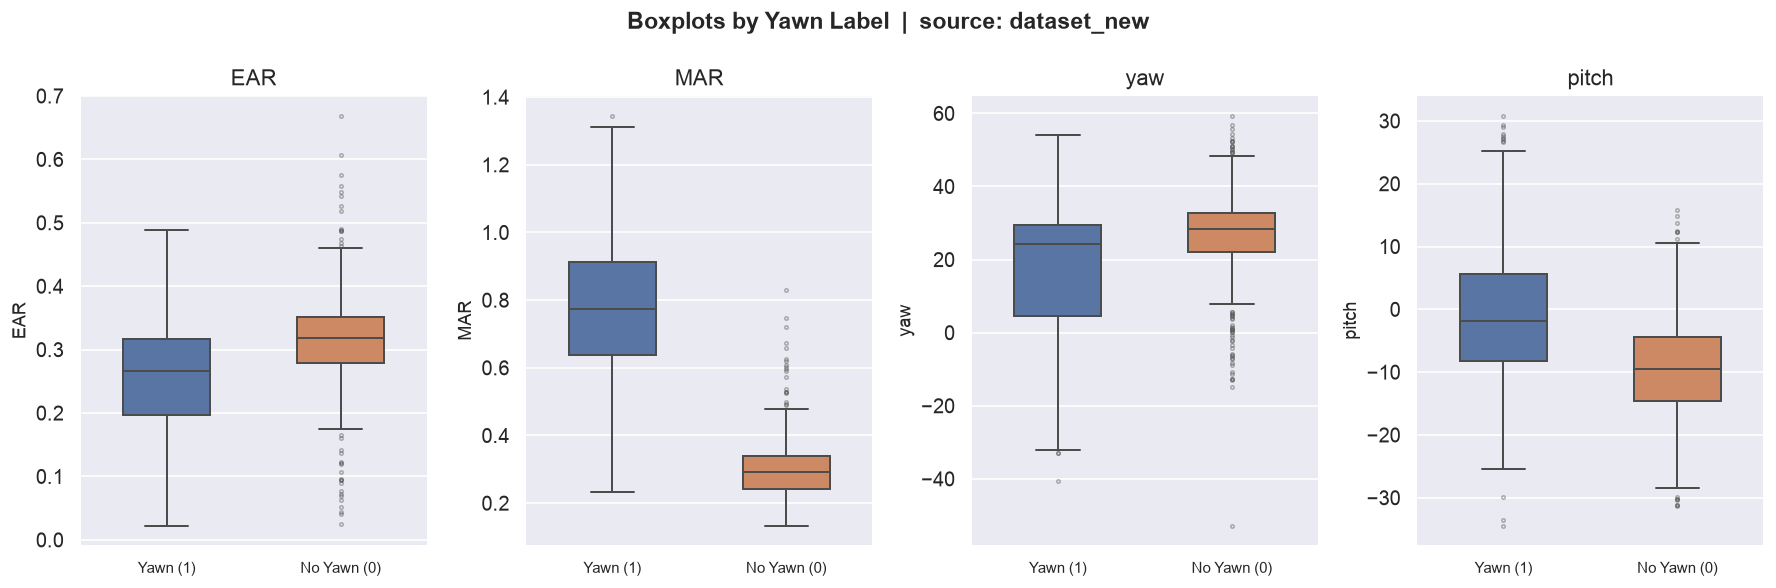

In [4]:
df_yawn = df_raw.dropna(subset=['yawn']).copy()
df_yawn['yawn_label'] = df_yawn['yawn'].astype(int).map({0: 'No Yawn (0)', 1: 'Yawn (1)'})

features = ['EAR', 'MAR', 'yaw', 'pitch']
fig, axes = plt.subplots(1, 4, figsize=(15, 5))

for ax, feat in zip(axes, features):
    sns.boxplot(
        data=df_yawn, x='yawn_label', y=feat, ax=ax,
        palette=['#4C72B0', '#DD8452'], width=0.5,
        linewidth=1.2, flierprops=dict(marker='o', markersize=2, alpha=0.4)
    )
    ax.set_title(feat)
    ax.set_xlabel('')
    ax.tick_params(axis='x', labelsize=9)

plt.suptitle('Boxplots by Yawn Label  |  source: dataset_new', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../results/boxplots_yawn.png', bbox_inches='tight')
plt.show()

### 3b. EAR / MAR / Yaw / Pitch  ×  Eyes Closed  (own recordings)

These boxplots compare features between **eyes open** (0) and **eyes closed** (1) frames from personal recordings.

- **EAR** should be the clearest discriminator: a lower EAR value means narrower eye opening.
- **MAR**, **Yaw**, and **Pitch** should remain similar across both classes since the mouth and head position are unrelated to whether the eyes are open or closed.

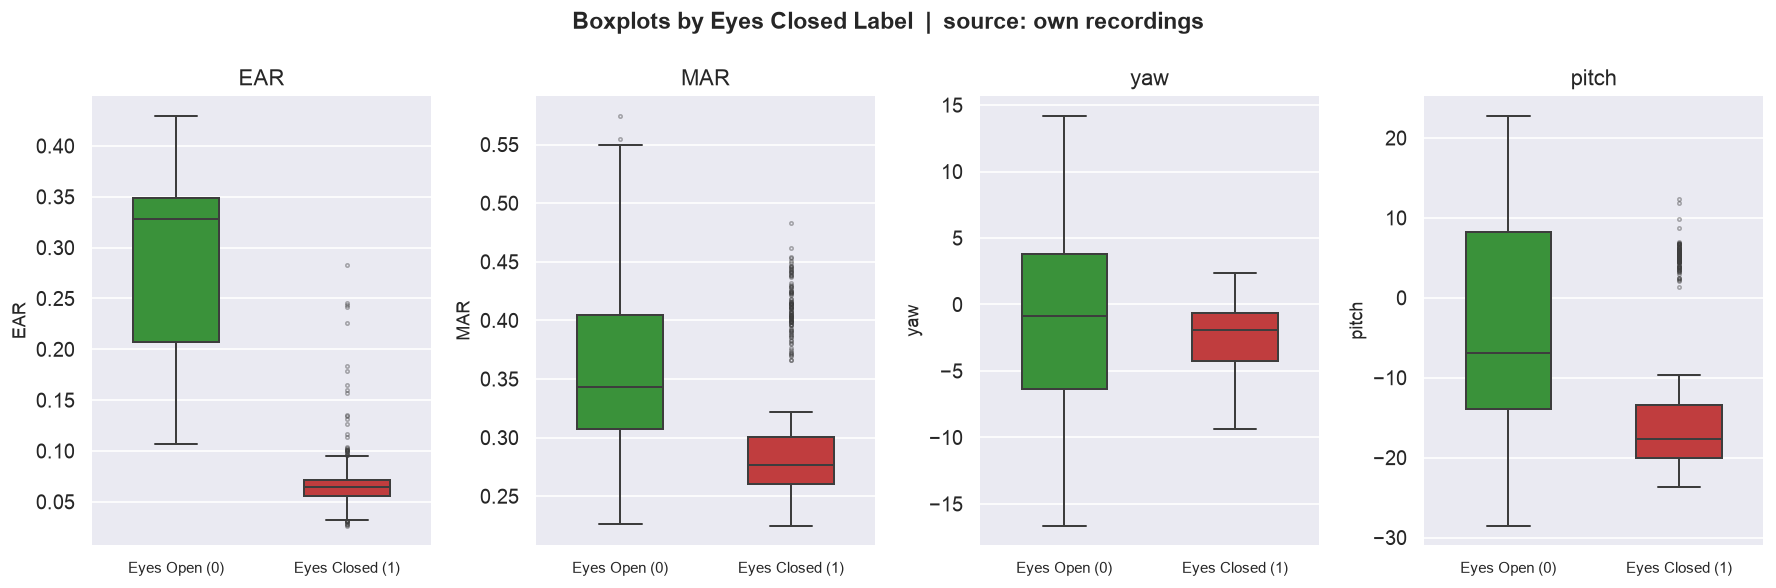

In [5]:
df_eyes = df_raw.dropna(subset=['eyes_closed']).copy()
df_eyes['eyes_label'] = df_eyes['eyes_closed'].astype(int).map({0: 'Eyes Open (0)', 1: 'Eyes Closed (1)'})

fig, axes = plt.subplots(1, 4, figsize=(15, 5))

for ax, feat in zip(axes, features):
    sns.boxplot(
        data=df_eyes, x='eyes_label', y=feat, ax=ax,
        palette=['#2ca02c', '#d62728'], width=0.5,
        linewidth=1.2, flierprops=dict(marker='o', markersize=2, alpha=0.4)
    )
    ax.set_title(feat)
    ax.set_xlabel('')
    ax.tick_params(axis='x', labelsize=9)

plt.suptitle('Boxplots by Eyes Closed Label  |  source: own recordings', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../results/boxplots_eyes_closed.png', bbox_inches='tight')
plt.show()

### 3c. EAR / MAR / Yaw / Pitch  ×  Looking Away  (own recordings)

These boxplots compare features between **facing forward** (0) and **looking away** (1) frames from personal recordings.

- **Yaw** should be the clearest discriminator: turning the head sideways shifts the yaw value significantly.
- **Pitch** may also differ if looking up/down is included in `looking_away`.
- **EAR** and **MAR** should remain similar since eye/mouth state is unrelated to head direction.

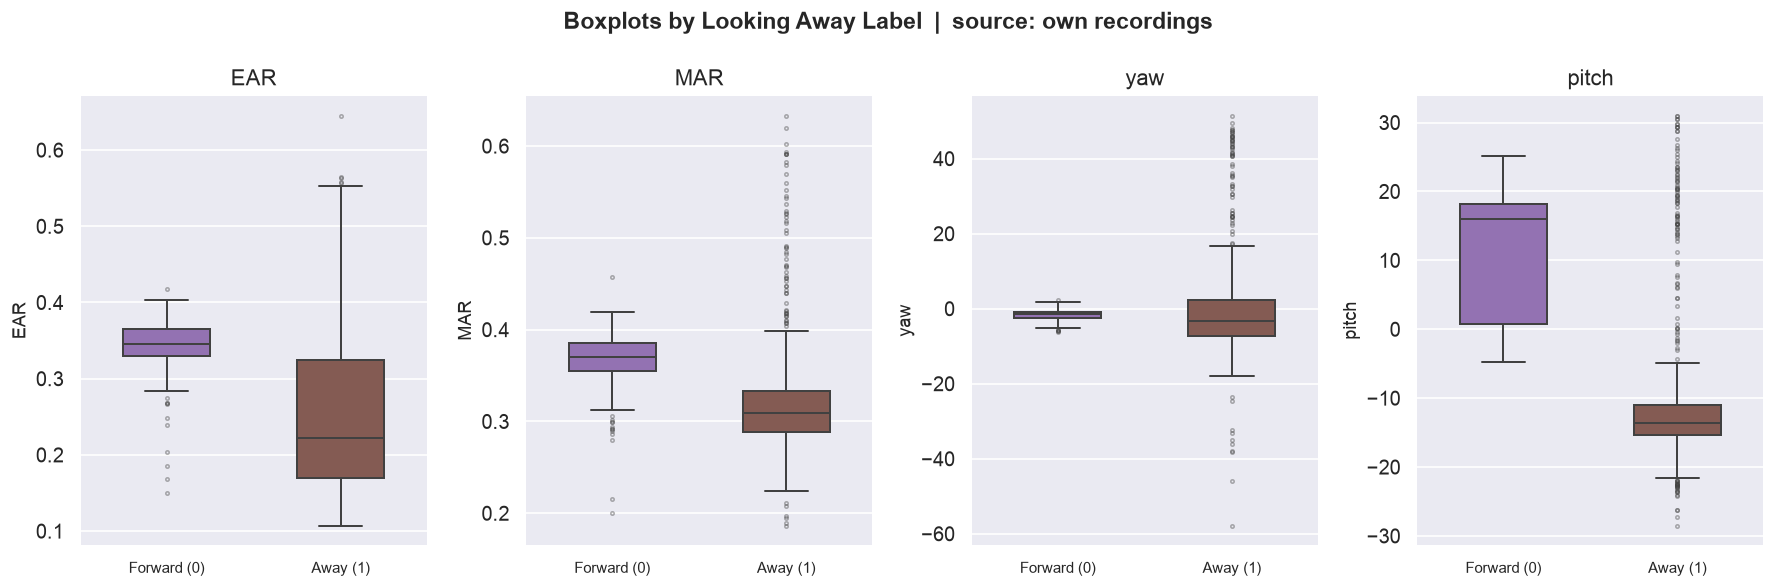

In [6]:
df_look = df_raw.dropna(subset=['looking_away']).copy()
df_look['look_label'] = df_look['looking_away'].astype(int).map({0: 'Forward (0)', 1: 'Away (1)'})

fig, axes = plt.subplots(1, 4, figsize=(15, 5))

for ax, feat in zip(axes, features):
    sns.boxplot(
        data=df_look, x='look_label', y=feat, ax=ax,
        palette=['#9467bd', '#8c564b'], width=0.5,
        linewidth=1.2, flierprops=dict(marker='o', markersize=2, alpha=0.4)
    )
    ax.set_title(feat)
    ax.set_xlabel('')
    ax.tick_params(axis='x', labelsize=9)

plt.suptitle('Boxplots by Looking Away Label  |  source: own recordings', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../results/boxplots_looking_away.png', bbox_inches='tight')
plt.show()

## 4. Correlation Heatmap

The heatmap shows Pearson correlation coefficients between every numeric column. Values close to **+1** mean the two features move together; values close to **-1** mean they move in opposite directions; values near **0** mean no linear relationship.

Key things to look for:
- **EAR ↔ eyes_closed**: Should be strongly negative — lower EAR means eyes are more closed.
- **MAR ↔ yawn**: Should be strongly positive — higher MAR means the mouth is more open.
- **Yaw ↔ looking_away**: Should be moderately correlated — looking away involves turning the head.
- **EAR ↔ MAR**: Should be near 0 — eye opening and mouth opening are independent.

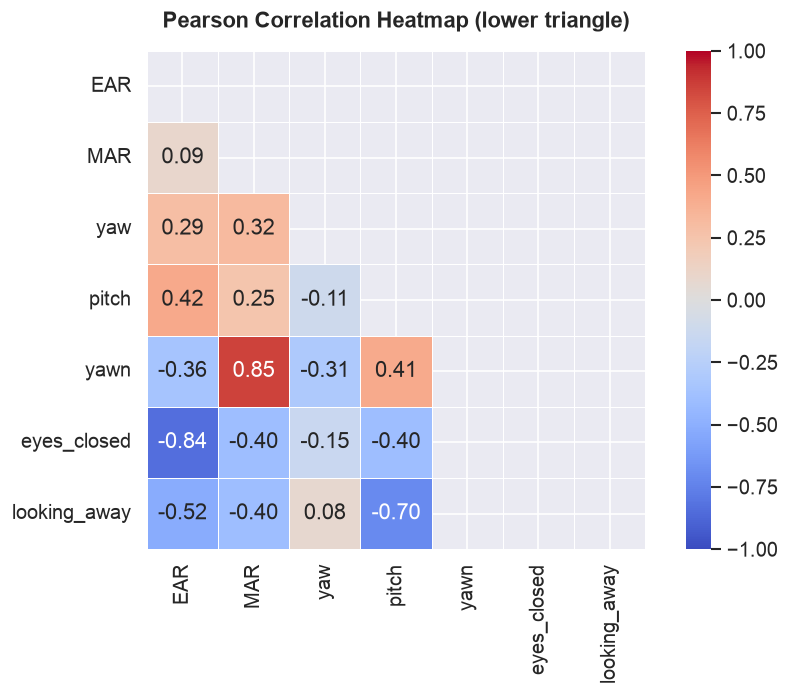

In [7]:
numeric_cols = ['EAR', 'MAR', 'yaw', 'pitch', 'yawn', 'eyes_closed', 'looking_away']
df_corr = df_raw[numeric_cols].apply(pd.to_numeric, errors='coerce')

corr = df_corr.corr()

mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    linecolor='white',
    square=True,
    ax=ax,
    vmin=-1,
    vmax=1,
)
ax.set_title('Pearson Correlation Heatmap (lower triangle)', fontsize=13, fontweight='bold', pad=14)
plt.tight_layout()
plt.savefig('../results/correlation_heatmap.png', bbox_inches='tight')
plt.show()

## 5. Pair Scatter — EAR vs MAR, coloured by Yawn

This scatter plot shows every row from `dataset_new` plotted by **EAR** (x-axis) vs **MAR** (y-axis), coloured by the yawn label. A clear visual separation between the two classes means the features alone are sufficient for a simple classifier. Overlap in the middle indicates harder cases where a more sophisticated model will be needed.

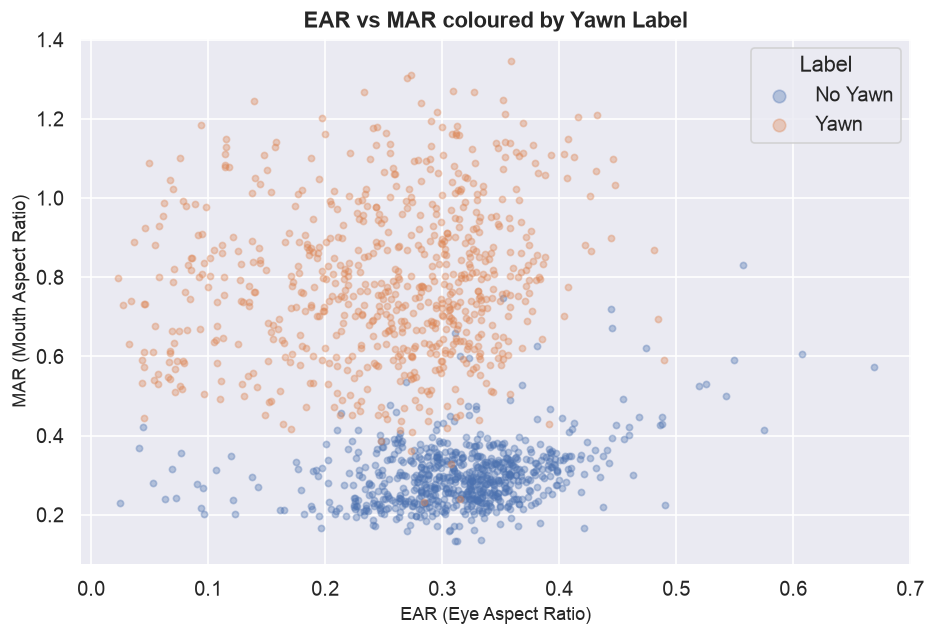

In [8]:
df_yawn2 = df_raw.dropna(subset=['yawn']).copy()
df_yawn2['Yawn'] = df_yawn2['yawn'].astype(int).map({0: 'No Yawn', 1: 'Yawn'})

fig, ax = plt.subplots(figsize=(8, 5.5))
for label, grp in df_yawn2.groupby('Yawn'):
    ax.scatter(
        grp['EAR'], grp['MAR'],
        label=label, alpha=0.35, s=14,
        color='#DD8452' if label == 'Yawn' else '#4C72B0'
    )

ax.set_xlabel('EAR (Eye Aspect Ratio)')
ax.set_ylabel('MAR (Mouth Aspect Ratio)')
ax.set_title('EAR vs MAR coloured by Yawn Label', fontweight='bold')
ax.legend(title='Label', markerscale=2)
plt.tight_layout()
plt.savefig('../results/scatter_ear_mar.png', bbox_inches='tight')
plt.show()

## 6. Descriptive Statistics

A quick numerical summary of each feature for the full dataset and broken down by source.
This confirms the expected value ranges seen in the boxplots:
- EAR ≈ 0.30 – 0.35 (open eyes), dropping toward 0.10 (closed eyes)
- MAR ≈ 0.30 – 0.40 (closed mouth), rising above 0.60 (yawning)
- Yaw and Pitch centred near 0 with spread depending on head movement range captured during recording

In [9]:
print('=== Full dataset ===')
display(df_raw[['EAR', 'MAR', 'yaw', 'pitch']].describe().round(4))

print('\n=== dataset_new ===')
display(df_raw[df_raw['source'] == 'dataset_new'][['EAR', 'MAR', 'yaw', 'pitch']].describe().round(4))

print('\n=== own recordings ===')
display(df_raw[df_raw['source'] == 'own'][['EAR', 'MAR', 'yaw', 'pitch']].describe().round(4))

=== Full dataset ===


,EAR,MAR,yaw,pitch
count,3534.0000,3534.0000,3534.0000,3534.0000
mean,0.2637,0.4248,8.8077,-3.0444
std,0.1137,0.2121,15.8275,13.0883
min,0.0226,0.1339,-57.8070,-34.4261
25%,0.1855,0.2897,-2.2997,-14.0307
50%,0.3044,0.3586,1.3870,-4.4682
75%,0.3452,0.4325,24.4124,6.5235
max,0.6687,1.3448,59.3500,30.9850



=== dataset_new ===


,EAR,MAR,yaw,pitch
count,1429.0000,1429.0000,1429.0000,1429.0000
mean,0.2829,0.5417,22.8363,-5.3418
std,0.0876,0.2865,13.7783,10.3499
min,0.0226,0.1339,-52.7752,-34.4261
25%,0.2420,0.2898,17.6012,-11.9681
50%,0.2970,0.4522,26.2592,-6.3685
75%,0.3367,0.7739,31.6992,0.2830
max,0.6687,1.3448,59.3500,30.8208



=== own recordings ===


,EAR,MAR,yaw,pitch
count,2105.0000,2105.0000,2105.0000,2105.0000
mean,0.2506,0.3455,-0.7157,-1.4848
std,0.1269,0.0652,8.2099,14.4543
min,0.0267,0.1866,-57.8070,-28.4950
25%,0.1314,0.2893,-3.8866,-14.5911
50%,0.3152,0.3462,-1.3983,-0.2948
75%,0.3476,0.3930,0.9257,12.6173
max,0.6450,0.6330,51.4309,30.9850
